count        20.00000
mean      62100.00000
std       49085.21055
min       32000.00000
25%       40750.00000
50%       47000.00000
75%       55750.00000
max      220000.00000
Name: salary, dtype: float64


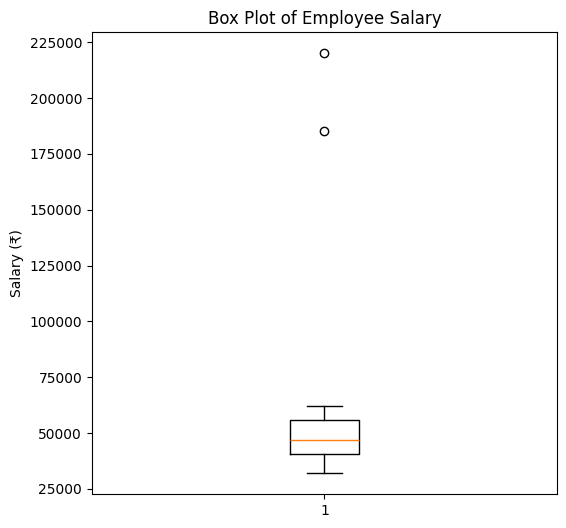

Q1=40750.0, Q3=55750.0, IQR=15000.0
Lower bound=18250.0, Upper bound=78250.0
    emp_id  salary
18      19  185000
19      20  220000
Mean with outliers: 62100.0 | without: 46500.0
Median with outliers: 47000.0 | without: 45500.0


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Sample employee salary data (₹)
salaries = [32,35,36,38,40,41,42,43,45,46,48,50,52,54,55,58,60,62,185,220]
df = pd.DataFrame({
    "emp_id": range(1, 21),
    "salary": [s * 1000 for s in salaries],
})
df.to_csv("employee_salary.csv", index=False)

data = df["salary"]
print(data.describe())

# Box plot
plt.figure(figsize=(6,6))
plt.boxplot(data, vert=True)
plt.title("Box Plot of Employee Salary")
plt.ylabel("Salary (₹)")
plt.savefig("boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

# Identify outliers using the IQR rule
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print(f"Q1={Q1}, Q3={Q3}, IQR={IQR}")
print(f"Lower bound={lower}, Upper bound={upper}")

outliers = df[(data < lower) | (data > upper)]
print(outliers)

# Impact check (do NOT remove automatically)
clean = data[(data >= lower) & (data <= upper)]
print("Mean with outliers:", data.mean(), "| without:", clean.mean())
print("Median with outliers:", data.median(), "| without:", clean.median())